# Neural Networks in PyTorch — Part 2
### Custom Architectures, Evaluation & Monitoring

**Session length:** ~120 minutes


## What we're covering today

- Where `nn.Sequential` breaks down — and what a custom `nn.Module` buys us
- Building a branching (multi-input/output) architecture, by hand
- `model.eval()` + `torch.no_grad()` — evaluating and predicting with a trained model
- **The double-softmax bug** — a prediction, an experiment, a real "aha"
- Monitoring and controlling training: early stopping & checkpointing inside your own loop
- TensorBoard, the PyTorch way


## Setup — picking up where Part 1 left off

If you're continuing in the same runtime as Part 1, you can skip straight to the next section. Otherwise, run this block to rebuild the data pipeline and the baseline model we ended Part 1 with — nothing here is new, it's a condensed replay.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything()

!wget "https://drive.google.com/uc?export=download&id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU" -O healthyfime.csv
df = pd.read_csv("healthyfime.csv")

df.replace({"M": 0, "F": 1}, inplace=True)
classes = list(df['class'].unique())
mapping_dict = {ch: i for i, ch in enumerate(sorted(classes, reverse=True))}
df['class'].replace(mapping_dict, inplace=True)

X, y = df.iloc[:, :-1], df.iloc[:, -1]
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.1, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.long)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)

--2026-10-07 13:22:45--  https://drive.google.com/uc?export=download&id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU
Resolving drive.google.com (drive.google.com)... 142.251.167.139, 142.251.167.100, 142.251.167.101, ...
Connecting to drive.google.com (drive.google.com)|142.251.167.139|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU&export=download [following]
--2026-10-07 13:22:45--  https://drive.usercontent.google.com/download?id=1GVhrh2rH6hUunV4Tf7lQoSFsqov9aPjU&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 192.178.218.132, 2607:f8b0:4004:c25::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|192.178.218.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 761835 (744K) [application/octet-stream]
Saving to: ‘healthyfime.csv’

healthyfime.csv     100%[===================>] 743.98K  --

/tmp/ipykernel_820/409210731.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({"M": 0, "F": 1}, inplace=True)
/tmp/ipykernel_820/409210731.py:24: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['class'].replace(mapping_dict, inplace=True)
/tmp/ipykernel_820/409210731.py:24: FutureWar

In [ ]:
# Rebuild + retrain the baseline model from Part 1
baseline_model = nn.Sequential(
    nn.Linear(11, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 4)
)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=0.001)

n_epochs = 500
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(n_epochs):
    baseline_model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = criterion(baseline_model(xb), yb)
        loss.backward()
        optimizer.step()

    baseline_model.eval()
    with torch.no_grad():
        tr_preds, va_preds = baseline_model(X_train_t), baseline_model(X_val_t)
        history["train_loss"].append(criterion(tr_preds, y_train_t).item())
        history["val_loss"].append(criterion(va_preds, y_val_t).item())
        history["train_acc"].append((tr_preds.argmax(1) == y_train_t).float().mean().item())
        history["val_acc"].append((va_preds.argmax(1) == y_val_t).float().mean().item())

print("Baseline trained. Final val accuracy:", round(history["val_acc"][-1], 4))

Baseline trained. Final val accuracy: 0.7529


## When one straight chain isn't enough

**Question for chat:** our baseline model is one input → one output, strictly sequential. What if Healthyfi.me asked you to also predict a *second* target at the same time — say, a continuous fitness score, alongside the A/B/C/D class? Or what if two feature groups needed separate processing before combining? Could `nn.Sequential` handle that?

**EXPECTED RESPONSE:** no — `Sequential` is a single chain, each layer's output feeds the next layer's input, nothing else. It can't branch, merge, or juggle more than one input/output.

This is exactly where `nn.Sequential` runs out of expressive power. PyTorch's answer is to write your own `nn.Module` subclass with a custom `forward()` method — one flexible building block that can express any architecture, branching included, not a specialized tool you only reach for in unusual cases.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/929/original/img1.png?1790159491" width="800">

---
### QUIZ 1

**You need a model that takes two separate feature groups — say, body-metrics and performance-metrics — through separate branches before producing predictions. Which PyTorch approach fits, and why?**

a) Subclass `nn.Module` and write a custom `forward()` method, since the computation graph branches instead of running as one straight chain.

b) Use `nn.Sequential` with two separate layer lists, since `Sequential` supports multiple parallel branches out of the box.

c) This isn't possible in PyTorch without a third-party library, since `nn.Module` only supports single-input, single-output models.

d) Stack all layers from both branches into one long `nn.Sequential`, in any order — the framework will infer the branching automatically.

**Correct answer: a**

`nn.Sequential` is, by design, a single linear chain of layers. The moment an architecture branches, merges, or needs multiple inputs/outputs, you need explicit control over how data flows — which is exactly what writing your own `forward()` gives you. Option (b) misattributes branching support to `Sequential`, (c) is simply false (this is core `nn.Module` capability, no extra library needed), and (d) misunderstands what `Sequential` does — it only ever chains one output into the next input, it never infers branching.

---

## Building a custom `nn.Module`

Let's first rebuild our *existing* baseline model as a custom class — same architecture, same result, just to see the mechanics before we add any branching.

In [ ]:
class WorkoutClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(11, 32)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(32, 16)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(16, 4)

    def forward(self, x):
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)
        return x

model_class_version = WorkoutClassifier()
print(model_class_version)

WorkoutClassifier(
  (fc1): Linear(in_features=11, out_features=32, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=32, out_features=16, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=16, out_features=4, bias=True)
)


**FOLLOW-UP:** "What does `__init__()` actually do here — does it run the model?"

**EXPECTED RESPONSE:** no — `__init__()` just creates and registers the layers as attributes, so PyTorch knows to track their parameters. `forward()` is what actually defines execution order.

**COMMON MISCONCEPTION:** learners sometimes assume layers run in the order they're listed in `__init__()`. They don't — `__init__()` is just object creation. Execution order is whatever `forward()` says, line by line.

Now the payoff — a genuinely branching model, with two separate inputs and two separate outputs:

In [ ]:
class MultiBranchModel(nn.Module):
    def __init__(self):
        super().__init__()
        # Branch 1: e.g. body-metrics features (11-d)
        self.branch1_fc1 = nn.Linear(11, 16)
        self.branch1_fc2 = nn.Linear(16, 4)
        # Branch 2: e.g. performance-metrics features (5-d)
        self.branch2_fc1 = nn.Linear(5, 4)

        self.out1 = nn.Linear(4, 4)   # e.g. classification head (4 classes)
        self.out2 = nn.Linear(4, 1)   # e.g. regression head (a continuous score)

    def forward(self, x1, x2):
        h1 = torch.relu(self.branch1_fc1(x1))
        h1 = torch.relu(self.branch1_fc2(h1))
        h2 = torch.tanh(self.branch2_fc1(x2))

        out1 = self.out1(h1)   # raw logits for classification
        out2 = self.out2(h2)   # raw value for regression
        return out1, out2

multi_model = MultiBranchModel()
dummy_x1 = torch.randn(8, 11)
dummy_x2 = torch.randn(8, 5)
logits, score = multi_model(dummy_x1, dummy_x2)
print(logits.shape, score.shape)

torch.Size([8, 4]) torch.Size([8, 1])


Two inputs in, two outputs out, two completely independent processing paths in between — `forward()` just describes the graph directly. This is the entire "Functional API" story in PyTorch: there's no second API to learn, only a more expressive way to use the one you already have.

**Industry connection:** this pattern shows up constantly in production — a recommendation model combining user features and item features through separate towers, or a model predicting both a category and a price from the same input. Branching architectures are the norm once you're past toy problems.

---
###QUIZ 2

**In a custom `nn.Module` subclass, what determines the order in which layers are actually applied when the model runs?**

a) The order the layers are defined as attributes inside `__init__()`.

b) The order Python garbage-collects the layer objects after the class is instantiated.

c) Alphabetical order of the layer attribute names.

d) Whatever order you write the operations in `forward()` — `__init__()` only creates the layers, it doesn't run them.

**Correct answer: d**

`__init__()` registers layers as attributes so PyTorch can track their parameters — it defines *what exists*, not *what runs when*. `forward()` is where you decide how data actually flows, including any branching, skipping, or merging. That's precisely what makes custom modules more flexible than `Sequential`: `forward()` can express things a flat attribute list never could.

---

## Prediction & evaluation, the PyTorch way

Back to our trained `baseline_model`. Now we need to check how well it's actually doing — on data it was trained on, and on data it's never seen. In PyTorch, that means writing a couple of small, reusable functions ourselves, using tools we've already met.

**Question for chat:** what do `model.eval()` and `torch.no_grad()` each actually do, and why do we need both?

**EXPECTED RESPONSE:** `model.eval()` switches certain layers' *behavior* (relevant once your architecture has layers like dropout/batchnorm); `torch.no_grad()` turns *off gradient tracking*, since evaluation never calls `.backward()`. They solve different problems and are usually used together.

In [ ]:
def evaluate_model(model, X_t, y_t, criterion):
    model.eval() # 1. Switch layers to evaluation mode
    with torch.no_grad(): # 2. Turn off gradient tracking to save memory/speed up inference
        preds = model(X_t)
        loss = criterion(preds, y_t).item()
        acc = (preds.argmax(1) == y_t).float().mean().item()
    return loss, acc

for name, Xs, ys in [("Train", X_train_t, y_train_t), ("Val", X_val_t, y_val_t), ("Test", X_test_t, y_test_t)]:
    loss, acc = evaluate_model(baseline_model, Xs, ys, criterion)
    print(f"{name:5s} — loss: {loss:.4f}  accuracy: {acc:.4f}")

Train — loss: 0.5228  accuracy: 0.7913
Val   — loss: 0.5944  accuracy: 0.7529
Test  — loss: 0.6214  accuracy: 0.7619


Notice `evaluate_model` is exactly the end-of-epoch block from Part 1's training loop, pulled out into a reusable function — that's really all \"evaluating a model\" involves: a forward pass, with gradient tracking switched off.

In [ ]:
baseline_model.eval()
with torch.no_grad():
    logits = baseline_model(X_test_t)
    probs = torch.softmax(logits, dim=1)
    pred_class = probs.argmax(dim=1)

print("Sum of probabilities per row (should be ~1):", probs.sum(dim=1)[:5])
print("Predicted classes:", pred_class[:10])

acc_score = accuracy_score(y_test_t.numpy(), pred_class.numpy())
print("Cross-checked test accuracy:", acc_score)

Sum of probabilities per row (should be ~1): tensor([1., 1., 1., 1., 1.])
Predicted classes: tensor([0, 3, 2, 1, 0, 3, 2, 3, 1, 3])
Cross-checked test accuracy: 0.7619402985074627


Our model was trained to output raw **logits**, not probabilities — that was a deliberate choice back in Part 1, since `nn.CrossEntropyLoss` needs logits. So to get human-readable probabilities for display, we apply `softmax` ourselves, *only at inference time*, never inside the model itself.

**FOLLOW-UP:** "Did we actually need that `softmax` call to get the predicted class?"

**EXPECTED RESPONSE:** no — `softmax` preserves order, so `argmax(logits)` and `argmax(softmax(logits))` always agree. We only needed it to see interpretable probability values, not to pick the class.

Hold onto that "softmax, only at inference, never inside the model" idea — we're about to find out what happens if you forget it.

---
### QUIZ 3

**Why do we wrap predictions with `torch.no_grad()` during evaluation and inference, instead of leaving autograd tracking on?**

a) Because `torch.no_grad()` is required syntax — PyTorch will throw an error on any forward pass without it.

b) Because we're not calling `.backward()` during evaluation, so tracking gradients would only waste memory and compute for no benefit.

c) Because `no_grad()` is what actually switches the model from training mode to evaluation mode.

d) Because it forces the model to use the full test set instead of mini-batches.

**Correct answer: b**

Autograd tracks every operation so a gradient can be computed later — but evaluation and inference never call `.backward()`, so that bookkeeping is pure overhead. `no_grad()` switches it off temporarily. It's unrelated to batching (ruling out d), it isn't required syntax — code runs without it, just heavier (ruling out a) — and train/eval mode switching is a separate call, `model.train()`/`model.eval()` (ruling out c).

---

## WOW FACTOR — the double-softmax bug

**Prediction, before we run anything:** our model currently ends in raw logits, feeding `nn.CrossEntropyLoss`. Softmax is the function that turns logits into probabilities — and probabilities feel like the more "complete," proper thing to hand a loss function. What do you think happens if we add one more layer — `nn.Softmax(dim=1)` — right at the end, so the model outputs probabilities directly?

**Chat prediction first. No peeking at the code below until you've guessed.**

**COMMON MISCONCEPTION:** "It should either do nothing (softmax is just normalization) or help (the loss function gets nicer values to work with)." Both feel intuitive. Neither is right.

In [ ]:
# Same architecture as our baseline, with one addition: a Softmax layer before the loss
flawed_model = nn.Sequential(
    nn.Linear(11, 32),
    nn.ReLU(),
    nn.Linear(32, 16),
    nn.ReLU(),
    nn.Linear(16, 4),
    nn.Softmax(dim=1)   # <-- the one-line change
)

seed_everything()
optimizer_flawed = torch.optim.Adam(flawed_model.parameters(), lr=0.001)
history_flawed = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

n_epochs_demo = 100  # shorter run — the effect is visible well before 500 epochs

for epoch in range(n_epochs_demo):
    flawed_model.train()
    for xb, yb in train_loader:
        optimizer_flawed.zero_grad()
        loss = criterion(flawed_model(xb), yb)   # still nn.CrossEntropyLoss
        loss.backward()
        optimizer_flawed.step()

    flawed_model.eval()
    with torch.no_grad():
        tr_preds, va_preds = flawed_model(X_train_t), flawed_model(X_val_t)
        history_flawed["train_loss"].append(criterion(tr_preds, y_train_t).item())
        history_flawed["val_loss"].append(criterion(va_preds, y_val_t).item())
        history_flawed["train_acc"].append((tr_preds.argmax(1) == y_train_t).float().mean().item())
        history_flawed["val_acc"].append((va_preds.argmax(1) == y_val_t).float().mean().item())

print("Flawed model — final val accuracy:", round(history_flawed["val_acc"][-1], 4))
print("Baseline (first", n_epochs_demo, "epochs) — val accuracy:", round(history["val_acc"][n_epochs_demo - 1], 4))

Flawed model — final val accuracy: 0.7554
Baseline (first 100 epochs) — val accuracy: 0.7579


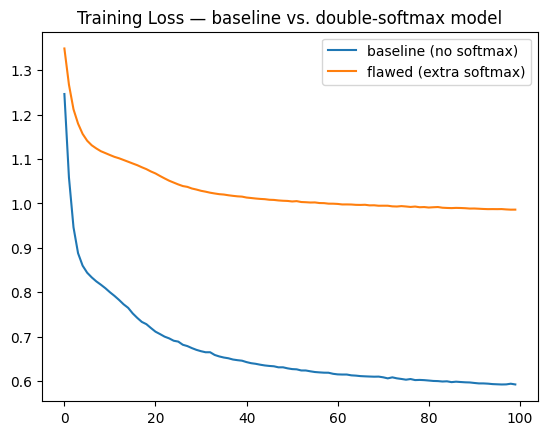

In [ ]:
plt.figure()
plt.plot(history["train_loss"][:n_epochs_demo], label="baseline (no softmax)")
plt.plot(history_flawed["train_loss"], label="flawed (extra softmax)")
plt.legend()
plt.title("Training Loss — baseline vs. double-softmax model")
plt.show()

### The Double-Softmax Effect Explained

`nn.CrossEntropyLoss` is not just a loss function — it internally combines two steps: `LogSoftmax`, then `NLLLoss`. It *already expects raw logits* and applies softmax itself, on the inside.

$$\text{CrossEntropyLoss}(x, y) = \text{NLLLoss}(\text{LogSoftmax}(x), y)$$

Add a `Softmax` layer to the model, and the loss function applies softmax to values that are *already* softmax output — squashed once, then squashed again. Softmax is **not idempotent**: applying it twice compresses the output distribution further, flattening the differences between classes and, with them, the gradient signal the optimizer relies on. It's the same underlying pattern as the vanishing-gradient recap from Part 1's warm-up — a transformation that pushes values into a range where derivatives go small, slowing learning down, not speeding it up.

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/946/original/img2.png?1790160803" width="800">

**Takeaway for the interview:** any time a loss function's documentation says it "expects raw logits" or "combines an activation internally," adding that activation yourself in the model is a bug, not extra safety. Always check what a loss function expects before deciding whether your output layer needs an activation at all.

---
### QUIZ 4

**You add an extra `nn.Softmax(dim=1)` as the final layer of your model, on top of the `nn.CrossEntropyLoss()` you're already using. What's the most likely effect on training?**

a) Training degrades — `CrossEntropyLoss` already applies softmax internally, so the model's raw scores get squashed twice, distorting the gradient signal.

b) No effect — softmax is idempotent, so applying it twice produces the exact same probabilities as applying it once.

c) Training improves — adding softmax explicitly gives the optimizer cleaner, already-normalized values to work with.

d) PyTorch will raise a shape-mismatch error, since `CrossEntropyLoss` can't accept softmax output as input.

**Correct answer: a**

`nn.CrossEntropyLoss` combines `LogSoftmax` and `NLLLoss` internally, so it expects raw logits. Feeding it already-softmaxed values means softmax gets applied a second time to numbers already squashed into [0, 1] — and softmax is not idempotent, so this distorts the loss landscape and weakens the gradient signal, exactly as we just watched happen. No shape error is raised (ruling out d), since the tensor's shape is unchanged — only its values are wrong.

---

## AI-assisted code review

**AI role:** reviews a custom `nn.Module` and flags what it considers issues

**Learner role:** evaluates whether each flagged issue is actually correct, using what we just covered

**Learning objective:** solidify custom-`forward()` design reasoning by checking AI output against it, rather than trusting it by default

**Guardrail:** learners must accept or reject each AI suggestion with their own justification — no suggestion gets applied automatically

Below is a custom multi-output model class. It has one genuine, meaningful bug — everything else about it is fine. See if you can spot the real issue and distinguish it from stylistic non-issues.

In [ ]:
class MultiOutputReviewModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.shared = nn.Linear(11, 16)
        self.class_head = nn.Linear(16, 4)     # classification output
        self.score_head = nn.Linear(16, 1)     # regression output

    def forward(self, x):
        h = torch.relu(self.shared(x))
        class_out = self.class_head(h)
        score_out = torch.relu(self.score_head(h))   # <-- worth a second look
        return class_out, score_out

**Chat prompt:** "Paste this into your AI assistant and ask it to review the class for correctness. Does it catch that `score_out` has a `relu` applied, even though this is meant to be an unconstrained regression output (a continuous score that could reasonably be negative)? Does it explain *why* that's a problem, or just that it looks unusual?"

**EXPECTED RESPONSE:** the bug is the stray `relu` on the regression head — it clips any negative predictions to zero, which is wrong unless the target is known to be non-negative. `class_out` correctly stays as raw logits (for `CrossEntropyLoss`), so that part needs no changes.

## Monitoring and controlling training

Right now, our training loop runs for a fixed number of epochs and prints nothing except what we explicitly tell it to. In practice, we usually want more control than that: stopping early once the model stops improving, saving the best version we've seen so far, and logging progress somewhere durable. None of this needs a special mechanism — it's just more logic, added directly into the loop we already own.

**Question for chat:** "Look back at Part 1's training loop — the line `if epoch % 50 == 0: print(...)`. What was that giving us?" **EXPECTED RESPONSE:** periodic visibility into how training is progressing, without flooding the output by printing every single epoch.

That covers basic logging. Let's add two more pieces of training control that matter in almost every real project: **stopping early** once the model stops improving, and **saving the best version** of the model as we go — same idea, written directly where they're needed.

In [ ]:
model_es = nn.Sequential(
    nn.Linear(11, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 4)
)
optimizer_es = torch.optim.Adam(model_es.parameters(), lr=0.001)

best_val_loss = float("inf")
patience = 20
epochs_without_improvement = 0
n_epochs_es = 500

for epoch in range(n_epochs_es):
    model_es.train()
    for xb, yb in train_loader:
        optimizer_es.zero_grad()
        loss = criterion(model_es(xb), yb)
        loss.backward()
        optimizer_es.step()

    model_es.eval()
    with torch.no_grad():
        val_loss = criterion(model_es(X_val_t), y_val_t).item()

    # ---- ModelCheckpoint equivalent: save only when val_loss improves ----
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save(model_es.state_dict(), "best_model.pt")
    else:
        epochs_without_improvement += 1

    # ---- EarlyStopping equivalent: stop once patience runs out ----
    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch} — best val_loss: {best_val_loss:.4f}")
        break

Early stopping at epoch 220 — best val_loss: 0.5926


No special framework mechanism needed — just two small blocks of logic, sitting exactly where they're needed, in the loop you already own.

**Two more common training-control patterns, briefly:**
- **Logging progress to a file** → literally `open("log.csv", "a")` and write a row each epoch, so the record survives past your notebook session.
- **Adjusting the learning rate during training** → PyTorch's `torch.optim.lr_scheduler` module (e.g. `StepLR`, `ReduceLROnPlateau`) — we'll use these properly in a later module.

**Industry connection:** in a real training job, saving checkpoints isn't optional — a crashed job (GPU pre-emption, spot-instance eviction, an out-of-memory error hours in) with no checkpoint means starting from scratch. This one `torch.save` line is often the difference between losing 10 minutes and losing a day.

---
### QUIZ 5

**You're adding early-stopping logic to your PyTorch training loop, based on validation loss. Where should that check live?**

a) Inside the inner `for xb, yb in train_loader` loop, checked after every single batch.

b) Inside `__init__()` of the model class, before any training starts.

c) At the end of each epoch, after `val_loss` has been computed — comparing it against the best value seen so far.

d) Inside `optimizer.zero_grad()`, since gradients need to be reset before any comparison can happen.

**Correct answer: c**

Early stopping needs a stable, once-per-epoch validation signal — the same point where `val_loss` is already computed and logged in the loop. Checking after every batch (a) is noisy and far more expensive; `__init__()` (b) runs before training even begins, so there's no `val_loss` yet; and `zero_grad()` (d) is purely a gradient-reset call, unrelated to comparing validation performance across epochs.


---

## TensorBoard, the PyTorch way

TensorBoard is a tool for tracking metrics, weights, and model structure visually, as training runs. In PyTorch, you write to it directly from the loop — no special wrapper class needed.

In [ ]:
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter(log_dir="runs/workout_classifier")

model_tb = nn.Sequential(
    nn.Linear(11, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 4)
)
optimizer_tb = torch.optim.Adam(model_tb.parameters(), lr=0.001)

for epoch in range(100):
    model_tb.train()
    for xb, yb in train_loader:
        optimizer_tb.zero_grad()
        loss = criterion(model_tb(xb), yb)
        loss.backward()
        optimizer_tb.step()

    model_tb.eval()
    with torch.no_grad():
        val_loss = criterion(model_tb(X_val_t), y_val_t).item()
        val_acc = (model_tb(X_val_t).argmax(1) == y_val_t).float().mean().item()

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)
    writer.add_scalar("Accuracy/val", val_acc, epoch)

writer.close()

`add_scalar(tag, value, epoch)` is the whole mechanism — we choose exactly what gets logged, and when, which gives us full control over what shows up on the dashboard.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

In [ ]:
from tensorboard import notebook

# Launch TensorBoard on a fresh port (e.g., 6007 or 6008)
notebook.start("--logdir runs --port 6007")

<IPython.core.display.Javascript object>

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 3s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧

In [ ]:
import subprocess
subprocess.Popen(["tensorboard", "--logdir", "runs", "--port", "6006"])

<Popen: returncode: None args: ['tensorboard', '--logdir', 'runs', '--port',...>

In [ ]:
!lt --port 6006


your url is: https://shaky-roses-search.loca.lt
^C


**Dashboard tabs:**
- **Scalars** — loss and accuracy curves, same information as our manually plotted ones
- **Graphs** — the model structure (needs one `writer.add_graph(model, sample_input)` call, not shown here)
- **Histograms/Distributions** — weight and bias distributions over training, if logged with `add_histogram`

<img src="https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/241/964/original/img3.png?1790162643" width="800">

---
### QUIZ 6

**On your TensorBoard Scalars tab, you see the train loss curve steadily falling while the validation loss curve turns upward partway through training. What does this tell you?**

a) TensorBoard is misconfigured — loss curves should always move together.

b) You forgot to call `writer.close()`, so the dashboard is showing stale cached values.

c) The logging frequency is too high, causing the visual distortion.

d) The same overfitting signature you already diagnosed from the manually plotted curves — TensorBoard is just rendering the same numbers.

**Correct answer: d**

TensorBoard's Scalars tab reads the exact values you passed to `add_scalar()` each epoch — it's a different rendering of the same numbers already sitting in your `history` dict, not a different phenomenon. Diverging train/val curves mean exactly what they meant when you plotted them with `matplotlib`: overfitting.

---

## Recap — the whole two-part journey

- `nn.Sequential` builds a straight chain; a custom `nn.Module` with its own `forward()` can express any architecture, branching included
- Evaluating and predicting are just `model.eval()` + `torch.no_grad()` + a forward pass — worth writing as a small reusable function
- Logits vs. probabilities isn't cosmetic — `CrossEntropyLoss` already applies softmax internally, and adding it again quietly breaks training
- Stopping early, saving the best model, and logging progress don't need a special mechanism — they're just a few lines of logic, placed exactly where they're needed in the loop
- TensorBoard is just a place to send the same numbers you're already tracking, using `add_scalar()`

**Reflection prompt (chat):** across both sessions — what's one thing about how neural networks actually train that you now understand at a level you didn't before writing this loop yourself?